In [38]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [39]:

import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import os
from ipywidgets import interact
import ipywidgets as widgets
from typing import Optional, Tuple
from matplotlib.colors import TwoSlopeNorm
from scipy.optimize import curve_fit

library_bin = os.path.join(sys.prefix, "Library", "bin")
if os.path.exists(library_bin):
    os.environ["PATH"] = library_bin + os.path.pathsep + os.environ.get("PATH", "")
    if hasattr(os, "add_dll_directory"):
        try:
            os.add_dll_directory(library_bin)
        except OSError:
            pass
import tomopy

# Point sys.path to the repository root
repo_root = Path.cwd().parent
if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

import config
import src.phase_extraction as pe
import src.calibration as calib
import src.slit_analysis as sa

In [40]:
def _gaussian_1d(
    x: np.ndarray,
    amplitude: float,
    mean: float,
    sigma: float,
    offset: float,
) -> np.ndarray:
    """1D Gaussian model with vertical baseline offset."""
    return offset + amplitude * np.exp(-0.5 * ((x - mean) / sigma) ** 2)


def crop_phasemap_symmetric_gaussian(
    phase_map: np.ndarray,
    px_to_mm: float,
    height_mm: float = 4.0,
    crop_width_mm: Optional[float] = None,
    nozzle_edge_y: Optional[int] = None,
    avg_window_rows: int = 3,
    debug: bool = False,
) -> Tuple[np.ndarray, dict]:
    """Crops a phase map symmetrically around the center of a Gaussian fit

    evaluated at a specific height (default 4.0 mm) above the nozzle.

    Returns
    -------
    cropped_map : np.ndarray
        Symmetrically cropped 2D phase map where the center column is the
        Gaussian center.
    fit_info : dict
        Dictionary containing fit parameters (center_px, amplitude, sigma,
        offset, x_start, x_end).
    """
    arr = np.asarray(phase_map, dtype=np.float64)
    if arr.ndim != 2:
        raise ValueError(f"Expected 2D phase map, got shape {arr.shape}")

    h, w = arr.shape
    if px_to_mm <= 0:
        raise ValueError("px_to_mm must be positive")

    # 1. Locate the target row at height_mm above the nozzle
    if nozzle_edge_y is not None:
        # For raw images where nozzle exit is at nozzle_edge_y and jet flows upward (-y)
        target_row = int(round(nozzle_edge_y - height_mm / px_to_mm))
    else:
        # For formatted maps where row 0 is the nozzle exit and +y is upward
        target_row = int(round(height_mm / px_to_mm))

    target_row = int(np.clip(target_row, 0, h - 1))

    # Average a small window of rows to reduce high-frequency fringe noise
    half_win = max(1, avg_window_rows) // 2
    r_start = max(0, target_row - half_win)
    r_end = min(h, target_row + half_win + 1)
    profile = np.nanmean(arr[r_start:r_end, :], axis=0)

    # 2. Initial parameter guesses for the Gaussian fit
    x_px = np.arange(w, dtype=np.float64)

    # Estimate background from the outer 10% edges
    n_bg = max(5, int(0.10 * w))
    bg_guess = float(
        np.nanmedian(np.concatenate([profile[:n_bg], profile[-n_bg:]]))
    )
    profile_sub = profile - bg_guess

    p_max = float(np.nanmax(profile_sub))
    p_min = float(np.nanmin(profile_sub))

    # Detect polarity of the peak
    if abs(p_max) >= abs(p_min):
        amp_guess = p_max
        mean_guess = float(np.nanargmax(profile_sub))
    else:
        amp_guess = p_min
        mean_guess = float(np.nanargmin(profile_sub))

    # Initial sigma guess (approx 30% of frame width)
    sigma_guess = max(5.0, w * 0.30)
    p0 = [amp_guess, mean_guess, sigma_guess, bg_guess]

    # Fit Gaussian
    try:
        bounds = (
            [-np.inf, 0.0, 1.0, -np.inf],
            [np.inf, float(w - 1), float(w), np.inf],
        )
        popt, _ = curve_fit(_gaussian_1d, x_px, profile, p0=p0, bounds=bounds)
        amp_fit, center_x_fit, sigma_fit, offset_fit = popt
        fit_success = True
    except Exception as e:
        # Fallback to centroid/peak if fit fails
        amp_fit, center_x_fit, sigma_fit, offset_fit = (
            amp_guess,
            mean_guess,
            sigma_guess,
            bg_guess,
        )
        fit_success = False
        print(f"Warning: Gaussian fit failed ({e}), using centroid fallback.")

    center_c = int(round(center_x_fit))

    # 3. Maximal symmetric crop around center_x
    max_half_w = min(center_c, (w - 1) - center_c)

    if crop_width_mm is not None and px_to_mm > 0:
        target_half_w = int(round(0.5 * (crop_width_mm / px_to_mm)))
        half_w = min(target_half_w, max_half_w)
    else:
        half_w = max_half_w

    x_start = center_c - half_w
    x_end = center_c + half_w + 1  # Exclusive index for slicing

    cropped_map = arr[:, x_start:x_end].copy()
    center_in_crop = center_c - x_start

    fit_info = {
        "center_x_px": center_x_fit,
        "center_x_int": center_c,
        "amplitude": amp_fit,
        "sigma_px": sigma_fit,
        "offset": offset_fit,
        "x_start": x_start,
        "x_end": x_end,
        "half_width_px": half_w,
        "center_in_crop": center_in_crop,
        "row_idx": target_row,
        "fit_success": fit_success,
    }

    # 4. Debug Visualization
    if debug:
        fig, axes = plt.subplots(
            1, 2, figsize=(14, 5), facecolor="white", constrained_layout=True
        )

        # Panel 1: Gaussian Fit on 1D Profile
        x_mm_orig = (x_px - center_x_fit) * px_to_mm
        fit_curve = _gaussian_1d(x_px, amp_fit, center_x_fit, sigma_fit, offset_fit)

        axes[0].plot(
            x_px,
            profile,
            "b.",
            alpha=0.4,
            label=f"Profile @ y={height_mm:.2f} mm",
        )
        axes[0].plot(
            x_px,
            fit_curve,
            "r-",
            linewidth=2.0,
            label=f"Gaussian Fit (center={center_x_fit:.1f} px)",
        )
        axes[0].axvline(
            center_x_fit,
            color="black",
            linestyle="--",
            label="Center",
        )
        axes[0].axvline(
            x_start,
            color="green",
            linestyle=":",
            label="Crop Bounds",
        )
        axes[0].axvline(x_end - 1, color="green", linestyle=":")

        axes[0].set_title(
            f"1D Profile & Gaussian Fit (Height = {height_mm:.2f} mm)"
        )
        axes[0].set_xlabel("Original X [pixels]")
        axes[0].set_ylabel("Phase [rad]")
        axes[0].grid(True, alpha=0.3)
        axes[0].legend(loc="best", fontsize=9)

        # Panel 2: Symmetrically Cropped Phase Map
        crop_w_px = cropped_map.shape[1]
        x_crop_mm = (np.arange(crop_w_px) - center_in_crop) * px_to_mm
        y_crop_mm = np.arange(cropped_map.shape[0]) * px_to_mm

        extent_crop = [x_crop_mm[0], x_crop_mm[-1], y_crop_mm[0], y_crop_mm[-1]]
        vmax = np.nanpercentile(np.abs(cropped_map), 98.0)
        vmax = max(float(vmax), 1e-6)

        im = axes[1].imshow(
            cropped_map,
            origin="lower",
            extent=extent_crop,
            aspect="auto",
            cmap="seismic",
            vmin=-vmax,
            vmax=vmax,
        )
        axes[1].axvline(
            0.0,
            color="black",
            linestyle="--",
            linewidth=1.2,
            label="Symmetric Center",
        )
        axes[1].axhline(
            height_mm,
            color="orange",
            linestyle=":",
            linewidth=1.5,
            label=f"Fit Row ({height_mm} mm)",
        )

        axes[1].set_title(
            f"Symmetrically Cropped Map ({cropped_map.shape[1]} px wide)"
        )
        axes[1].set_xlabel("Relative X [mm] (0 = Center)")
        axes[1].set_ylabel("Height above nozzle [mm]")
        axes[1].legend(loc="upper right", fontsize=9)

        cbar = fig.colorbar(im, ax=axes[1])
        cbar.set_label("Phase [rad]")
        plt.show()

    return cropped_map, fit_info

# Single-Angle Phase Map Extraction & Verification

Unsupported data type for _convert.
Unsupported data type for _convert.


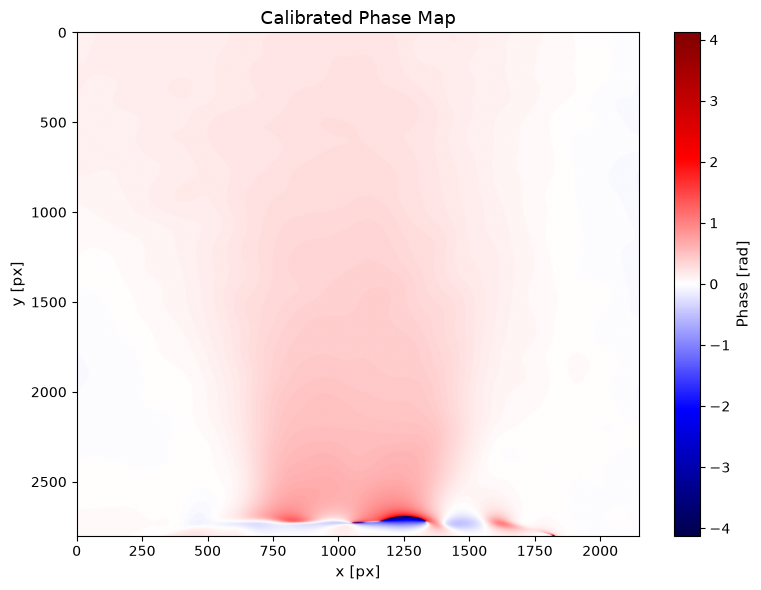

Detected Nozzle Edge (y-px): 2659
Detected Nozzle X-Range (px): [495, 1817]
Pixel-to-mm scaling factor: 0.004539 mm/px


In [43]:
# Path to 90 degree test scan
hdf5_path_90 = r"C:\Users\vmlab\Documents\data\files\2026\09\23\nozzle_153\Ar_5_bar\90_deg"

# Extract ROI and compute Fourier shift and phase unwrapping
roi = [2000, 5000, 1300, 3650]  # [x_start, x_end, y_start, y_end]
ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(hdf5_path_90, roi=roi)

ref_fourier_shifted = pe.get_fourier(ref_roi)
exp_fourier_shifted = pe.get_fourier(exp_roi)
dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug=False)

delta_phase_wrapped = pe.get_delta_phase_wrapped(
    ref_fourier_shifted, exp_fourier_shifted, dominant_frequency, debug=False
)

# Detect nozzle exit edge and horizontal bounds
y_edge, *_ = calib.estimate_nozzle_edge(ref_roi)
x_left, x_right = calib.detect_nozzle_x_range(ref_roi, y_edge, debug= False)

# Remove background tilt and zero the phase outside the jet
calibrated_phase_90, _ = calib.calibrate_phase(
    delta_phase_wrapped, y_edge, x_left, x_right, debug=True
)

# Spatial scaling calibration
NOZZLE_WIDTH_MM = 6.0
px_to_mm = calib.calculate_px_to_mm(x_left, x_right, NOZZLE_WIDTH_MM)

print(f"Detected Nozzle Edge (y-px): {y_edge}")
print(f"Detected Nozzle X-Range (px): [{x_left}, {x_right}]")
print(f"Pixel-to-mm scaling factor: {px_to_mm:.6f} mm/px")

In [ ]:
# Crop phase map up to 6.0 mm above nozzle and flip so y=0 is nozzle exit
MAX_HEIGHT_MM = 6.0
cropped_phase_90 = sa.crop_and_format_phase_map(
    calibrated_phase_90,
    nozzle_edge_y=y_edge,
    px_to_mm=px_to_mm,
    max_height_mm=MAX_HEIGHT_MM
)

# Visual check of calibrated 2D phase map
plt.figure(figsize=(10, 5))
plt.imshow(cropped_phase_90, origin="lower", cmap="seismic")
plt.title("Calibrated Phase Map (90° Scan, y=0 at Nozzle Exit Edge)")
plt.xlabel("X Pixel")
plt.ylabel("Height Above Nozzle Exit (Pixels)")
plt.colorbar(label="Phase [rad]")
plt.show()

# Batch Processing All 20 Angles using

In [ ]:
# List of 20 projection angles between -20° and 180°
angles_deg = [-20, -10, 0, 10, 20, 30, 40, 50, 60, 70, 80, 90, 100, 110, 120, 130, 140, 150, 160, 170, 180]
base_path = r"C:\Users\vmlab\Documents\data\files\2026\09\23\nozzle_153\Ar_5_bar"

calibrated_maps = []

for angle in angles_deg:
    folder_path = rf"{base_path}\{int(angle)}_deg"
    print(f"Processing angle {angle:+.1f}°: {folder_path}")

    # Extract images using phase_extraction
    ref_img, exp_img, ref_roi, exp_roi = pe.get_interferometry_images(folder_path, roi=roi)

    # Fourier transform & frequency shift
    ref_fourier_shifted = pe.get_fourier(ref_roi)
    exp_fourier_shifted = pe.get_fourier(exp_roi)
    dominant_frequency = pe.get_dominant_frequency(ref_fourier_shifted, debug=False)

    # Extract unwrapped delta phase difference
    delta_phase_wrapped = pe.get_delta_phase_wrapped(
        ref_fourier_shifted, exp_fourier_shifted, dominant_frequency, debug=False
    )

    # Background tilt removal using fixed 90° bounds
    calibrated_phase, _ = calib.calibrate_phase(
        delta_phase_wrapped,
        nozzle_edge_y=y_edge,
        nozzle_left_px=x_left,
        nozzle_right_px=x_right,
        debug=False
    )

    # Crop to standardized grid (y=0 at nozzle exit, max height = 6.0 mm)
    cropped_phase = sa.crop_and_format_phase_map(
        calibrated_phase,
        nozzle_edge_y=y_edge,
        px_to_mm=px_to_mm,
        max_height_mm=MAX_HEIGHT_MM
    )
    cropped_symmetric, fit_info = crop_phasemap_symmetric_gaussian(
        cropped_phase,
        px_to_mm=px_to_mm,
        height_mm=4.0,
        crop_width_mm=6.0,
        nozzle_edge_y=None,
        avg_window_rows=3,
        debug=True
    )
    calibrated_maps.append(cropped_symmetric)

# Enforce uniform dimensions across all views
min_h = min(m.shape[0] for m in calibrated_maps)
min_w = min(m.shape[1] for m in calibrated_maps)

# Stack into 3D array: (num_angles, height_px, width_px)
phase_stack = np.array([m[:min_h, :min_w] for m in calibrated_maps], dtype=np.float32)

print("\nPhase map extraction completed successfully.")
print(f"Output Stack Shape: {phase_stack.shape} (Angles, Height_px, Width_px)")

In [ ]:
# Physical coordinates
width_mm = min_w * px_to_mm
height_mm = min_h * px_to_mm
x_axis_mm = np.linspace(-width_mm / 2.0, width_mm / 2.0, min_w)
extent_mm = [x_axis_mm[0], x_axis_mm[-1], 0, height_mm]

# Target heights above nozzle exit to plot cross-sections (in mm)
cut_heights_mm = [0.5, 1.0, 2.0, 3.0]
cut_colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]


def view_angle(angle_idx=11):
    angle_val = angles_deg[angle_idx]
    pmap = phase_stack[angle_idx]

    # Diagnostics for this specific angle
    p_min = float(np.nanmin(pmap))
    p_max = float(np.nanmax(pmap))

    # Outer background check (first and last 100 pixels along x)
    bg_left = np.nanmean(pmap[:, :100])
    bg_right = np.nanmean(pmap[:, -100:])
    bg_offset = (bg_left + bg_right) / 2.0

    fig, (ax_map, ax_cuts) = plt.subplots(
        1, 2, figsize=(15, 6), facecolor="white"
    )

    # ---------------- 1. High-Resolution 2D Phase Map ----------------
    vmax = np.nanpercentile(np.abs(pmap), 99.0)
    vmax = max(float(vmax), 1.0)

    im = ax_map.imshow(
        pmap,
        origin="lower",
        extent=extent_mm,
        aspect="auto",
        cmap="seismic",
        vmin=-0.5,
        vmax=vmax,
    )

    ax_map.set_title(
        f"Angle: {angle_val:+.0f}° (Index {angle_idx}) — 2D Phase Map",
        fontsize=12,
        color="black",
    )
    ax_map.set_xlabel("x [mm]", color="black")
    ax_map.set_ylabel("Height above nozzle [mm]", color="black")
    ax_map.tick_params(colors="black")
    for spine in ax_map.spines.values():
        spine.set_color("black")

    cbar = fig.colorbar(im, ax=ax_map, fraction=0.046, pad=0.04)
    cbar.set_label("Phase [rad]", color="black")
    cbar.ax.yaxis.set_tick_params(color="black")
    plt.setp(plt.getp(cbar.ax.axes, "yticklabels"), color="black")

    # ---------------- 2. Horizontal Lineouts Across Jet ----------------
    for h_mm, col in zip(cut_heights_mm, cut_colors):
        iy = int(np.clip(round(h_mm / px_to_mm), 0, min_h - 1))
        profile = pmap[iy, :]

        # Plot lineout
        ax_cuts.plot(
            x_axis_mm,
            profile,
            label=f"y = {h_mm:.1f} mm",
            color=col,
            linewidth=1.8,
        )

        # Draw corresponding height line on 2D map
        ax_map.axhline(h_mm, color=col, linestyle="--", alpha=0.7)

    ax_cuts.axhline(0, color="gray", linestyle=":", alpha=0.7)
    ax_cuts.set_title(
        f"Horizontal Profiles at {angle_val:+.0f}°", fontsize=12, color="black"
    )
    ax_cuts.set_xlabel("x [mm]", color="black")
    ax_cuts.set_ylabel("Phase [rad]", color="black")
    ax_cuts.grid(True, linestyle=":", alpha=0.5)
    ax_cuts.legend(loc="upper right", framealpha=0.9)
    ax_cuts.tick_params(colors="black")
    for spine in ax_cuts.spines.values():
        spine.set_color("black")

    plt.tight_layout()
    plt.show()

    # Print summary readout
    print(
        f"Angle: {angle_val:>+6.1f}° (Index {angle_idx:>2d}) | "
        f"Min: {p_min:>6.2f} rad | Max: {p_max:>6.2f} rad | "
        f"Outer BG Offset: {bg_offset:>+7.4f} rad"
    )


# Interactive slider: drag or use keyboard Left/Right arrows to step 1 by 1
interact(
    view_angle,
    angle_idx=widgets.IntSlider(
        min=0,
        max=len(angles_deg) - 1,
        step=1,
        value=11,  # Starts at 90°
        description="Angle:",
        continuous_update=False,
    ),
)

# Verification & TomoPy Dataset Formatting

In [ ]:
# Projection angles in radians for TomoPy
theta_rad = np.radians(angles_deg)

# Estimate Center of Rotation (CoR) on a slice near the nozzle exit (slice index 10)
sample_slice_idx = 300
rot_center = tomopy.find_center(
    phase_stack,
    theta_rad,
    init=phase_stack.shape[2] / 2.0,
    ind=sample_slice_idx,
    tol=0.5
)

# Convert to float to avoid numpy array formatting error
# Convert rot_center from numpy array to float for string formatting
center_val = float(np.squeeze(rot_center))
print(f"Estimated Center of Rotation (CoR): {center_val:.2f} px")

# Visualize sinogram at sample height
plt.figure(figsize=(10, 5))
sinogram_slice = phase_stack[:, sample_slice_idx, :]
plt.imshow(
    sinogram_slice,
    aspect="auto",
    cmap="viridis",
    extent=[0, min_w, angles_deg[-1], angles_deg[0]]
)
plt.axvline(rot_center, color="red", linestyle="--", label=f"CoR ({center_val:.2f} px)")
plt.title(f"Sinogram at Slice {sample_slice_idx} ({sample_slice_idx * px_to_mm:.2f} mm above exit)")
plt.xlabel("X Pixel")
plt.ylabel("Rotation Angle (°)")
plt.colorbar(label="Phase Difference [rad]")
plt.legend()
plt.show()

# # Export dataset for TomoPy reconstruction
# output_dir = Path(r"C:\Users\vmlab\Documents\data\phase_maps\tomopy_prepared")
# output_dir.mkdir(parents=True, exist_ok=True)
#
# np.save(output_dir / "phase_stack_20angles.npy", phase_stack)
# np.save(output_dir / "theta_rad.npy", theta_rad)
# np.save(output_dir / "rot_center.npy", np.array([rot_center]))
# np.save(output_dir / "px_to_mm.npy", np.array([px_to_mm]))
#
# print(f"Saved TomoPy dataset to: {output_dir}")

In [22]:
# -----------------------------------------------------------------------------
# Cell: TomoPy 3D Reconstruction (SIRT Algorithm)
# -----------------------------------------------------------------------------
print("Running TomoPy 3D reconstruction with SIRT (200 iterations)...")

# tomopy.recon expects shape (num_angles, num_slices_y, num_x_pixels)
# Output shape: (num_slices_y, num_z_pixels, num_x_pixels)
rec_sirt = tomopy.recon(
    phase_stack,
    theta_rad,
    center=center_val,
    algorithm='sirt',
    num_iter=200
)

# Apply circular mask to clean outer boundary artifacts
rec_sirt = tomopy.circ_mask(rec_sirt, axis=0, ratio=0.95)

print("Reconstruction complete.")
print(f"Reconstructed 3D Volume Shape (Y-slices, Z-depth, X-width): {rec_sirt.shape}")

Running TomoPy 3D reconstruction with SIRT (200 iterations)...
Reconstruction complete.
Reconstructed 3D Volume Shape (Y-slices, Z-depth, X-width): (1322, 1323, 1323)


In [23]:
# -----------------------------------------------------------------------------
# Cell: Save the 3D Reconstruction to Disk
# -----------------------------------------------------------------------------
from pathlib import Path
import tomopy

# Create a dedicated output directory
out_dir = Path(r"C:\Users\vmlab\Documents\data\density_maps\tomopy_3D_reconstruction")
out_dir.mkdir(parents=True, exist_ok=True)

# 1. Save as a pure Python NumPy array
np.save(out_dir / "rec_sirt_raw.npy", rec_sirt)
print(f"Saved NumPy array to {out_dir}")

# 2. Save as a TIFF stack (1 image per vertical y-slice)
# This creates a folder full of .tiff images that you can drag-and-drop into ImageJ/Fiji
tiff_dir = out_dir / "tiff_stack"
tiff_dir.mkdir(exist_ok=True)
tomopy.write_tiff_stack(rec_sirt, fname=str(tiff_dir / 'slice'), axis=0, overwrite=True)
print(f"Saved 3D TIFF stack to {tiff_dir}")

Saved NumPy array to C:\Users\vmlab\Documents\data\density_maps\tomopy_3D_reconstruction


AttributeError: module 'tomopy' has no attribute 'write_tiff_stack'

In [24]:
# -----------------------------------------------------------------------------
# Cell: Convert TomoPy Voxels to Number Density (cm^-3)
# -----------------------------------------------------------------------------
# Physical constants for Argon gas
wavelength_m = 532e-9                 # 532 nm laser wavelength
gladstone_dale_argon = 1.57e-4        # Gladstone-Dale constant for Argon [m^3/kg]
M_argon = 39.95e-3                    # Molar mass of Argon [kg/mol]
N_A = 6.022e23                        # Avogadro constant [1/mol]

# Convert the pixel scaling to meters
px_to_m = px_to_mm * 1e-3

In [25]:
out_dir = Path(
    r"C:\Users\vmlab\Documents\data\density_maps\tomopy_3D_reconstruction"
)
raw_path = out_dir / "rec_sirt_raw.npy"

print(f"Loading raw reconstruction from {raw_path}...")
rec_sirt = np.load(raw_path)
print(f"Loaded rec_sirt with shape: {rec_sirt.shape}, dtype: {rec_sirt.dtype}")

Loading raw reconstruction from C:\Users\vmlab\Documents\data\density_maps\tomopy_3D_reconstruction\rec_sirt_raw.npy...
Loaded rec_sirt with shape: (1322, 1323, 1323), dtype: float32


In [26]:
# 2. Combined scalar conversion factor
conversion_factor = (wavelength_m / (2 * np.pi * px_to_m)) * (
    N_A / (gladstone_dale_argon * M_argon * 1e6)
)

print("Applying conversion factor in-place...")

# 3. In-place conversion and noise clipping (operates in RAM without creating copies)
rec_sirt *= conversion_factor
np.clip(rec_sirt, 0.0, None, out=rec_sirt)

# Reference as density_3d_cm3
density_3d_cm3 = rec_sirt

max_density = np.max(density_3d_cm3)
print(f"Peak Reconstructed Number Density: {max_density:.3e} cm^-3")

Applying conversion factor in-place...
Peak Reconstructed Number Density: 1.040e+19 cm^-3


In [ ]:
# -----------------------------------------------------------------------------
# Cell: Plot Orthogonal 3D Cross-Sections
# -----------------------------------------------------------------------------
# Find the geometric center of the matrix
center_y = density_3d_cm3.shape[0] // 4    # Pick a height (e.g., 1/4th up the nozzle)
center_z = density_3d_cm3.shape[1] // 2    # Minor axis center
center_x = density_3d_cm3.shape[2] // 2    # Major axis center

# Create physical extents for plotting axes in mm
z_len_mm = density_3d_cm3.shape[1] * px_to_mm
x_len_mm = density_3d_cm3.shape[2] * px_to_mm
y_len_mm = density_3d_cm3.shape[0] * px_to_mm

fig, axes = plt.subplots(1, 3, figsize=(18, 6), facecolor="white")
m_val = np.nanpercentile(density_3d_cm3, 99.5) # Color scaling

# 1. XZ Plane (Top-Down View looking into the nozzle)
im0 = axes[0].imshow(density_3d_cm3[center_y, :, :], cmap='viridis', origin='lower',
                     extent=[-x_len_mm/2, x_len_mm/2, -z_len_mm/2, z_len_mm/2], vmax=m_val)
axes[0].set_title(f"XZ Plane (Top-Down) at y={center_y * px_to_mm:.2f}mm", color="black")
axes[0].set_xlabel("X [mm]")
axes[0].set_ylabel("Z [mm]")

# 2. XY Plane (Front View - Slit Major Axis)
im1 = axes[1].imshow(density_3d_cm3[:, center_z, :], cmap='viridis', origin='lower', aspect='auto',
                     extent=[-x_len_mm/2, x_len_mm/2, 0, y_len_mm], vmax=m_val)
axes[1].set_title(f"XY Plane (Front View) at z=0mm", color="black")
axes[1].set_xlabel("X [mm]")
axes[1].set_ylabel("Height y [mm]")

# 3. YZ Plane (Side View - Slit Minor Axis)
im2 = axes[2].imshow(density_3d_cm3[:, :, center_x], cmap='viridis', origin='lower', aspect='auto',
                     extent=[-z_len_mm/2, z_len_mm/2, 0, y_len_mm], vmax=m_val)
axes[2].set_title(f"YZ Plane (Side View) at x=0mm", color="black")
axes[2].set_xlabel("Z [mm]")

for ax in axes:
    ax.tick_params(colors="black")
    for spine in ax.spines.values(): spine.set_color("black")

fig.colorbar(im2, ax=axes, orientation='horizontal', fraction=0.05, pad=0.1, label="Density $N$ [cm$^{-3}$]")
plt.show()

Sub-volume grid: (96, 111, 111) (Y x Z x X) with step=12
Peak density (y >= 0.8 mm): 7.744e+18 cm^-3
Plotly inline display unavailable (run 'pip install nbformat' to enable).


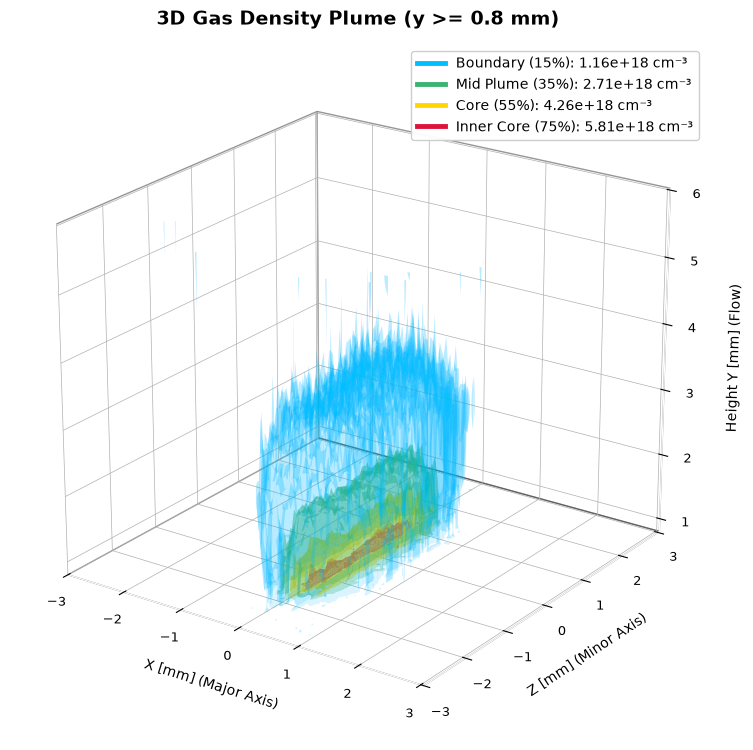

In [37]:
# %% [markdown]
# # 3D Multi-Isosurface Visualization with Density Values in Legend (y >= 0.8 mm)

# %%
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
import numpy as np
from skimage.measure import marching_cubes

# -------------------------------------------------------------------------
# 1. Coordinate Setup and Volume Slicing (y >= 0.8 mm)
# -------------------------------------------------------------------------
if "density_3d_cm3" not in locals():
    density_3d_cm3 = rec_sirt

scale = float(np.squeeze(px_to_mm))

# Cut at y = 0.8 mm to exclude near-nozzle shadow/diffraction artifacts
y_cutoff_mm = 0.8
slice_start = int(round(y_cutoff_mm / scale))
slice_start = min(slice_start, density_3d_cm3.shape[0] - 1)

# Centers of the matrix
center_z = density_3d_cm3.shape[1] // 2
center_x = density_3d_cm3.shape[2] // 2

# Horizontal bounding box (+/- 3.5 mm covers the jet expansion)
half_span_mm = 3.5
half_span_px = int(round(half_span_mm / scale))

z_min = max(0, center_z - half_span_px)
z_max = min(density_3d_cm3.shape[1], center_z + half_span_px + 1)
x_min = max(0, center_x - half_span_px)
x_max = min(density_3d_cm3.shape[2], center_x + half_span_px + 1)

# Auto-stride to keep rendering fast (< 1-2 sec)
max_dim = max(
    density_3d_cm3.shape[0] - slice_start, z_max - z_min, x_max - x_min
)
step = max(1, int(np.ceil(max_dim / 120)))

# Extract sub-volume
sub_vol = density_3d_cm3[
    slice_start::step, z_min:z_max:step, x_min:x_max:step
].astype(np.float32)

# Voxel step and physical boundaries in mm
voxel_step_mm = step * scale

x_start_mm = (x_min - center_x) * scale
z_start_mm = (z_min - center_z) * scale
y_start_mm = slice_start * scale

x_end_mm = x_start_mm + sub_vol.shape[2] * voxel_step_mm
z_end_mm = z_start_mm + sub_vol.shape[1] * voxel_step_mm
y_end_mm = y_start_mm + sub_vol.shape[0] * voxel_step_mm

peak_density = float(np.nanmax(sub_vol))
print(f"Sub-volume grid: {sub_vol.shape} (Y x Z x X) with step={step}")
print(f"Peak density (y >= {y_cutoff_mm} mm): {peak_density:.3e} cm^-3")

# -------------------------------------------------------------------------
# 2. Interactive 3D Plotly View (Safe Fallback)
# -------------------------------------------------------------------------
try:
    import plotly.graph_objects as go

    grid_y = np.linspace(y_start_mm, y_end_mm, sub_vol.shape[0])
    grid_z = np.linspace(z_start_mm, z_end_mm, sub_vol.shape[1])
    grid_x = np.linspace(x_start_mm, x_end_mm, sub_vol.shape[2])

    Y_grid, Z_grid, X_grid = np.meshgrid(grid_y, grid_z, grid_x, indexing="ij")

    fig_plotly = go.Figure(
        data=go.Isosurface(
            x=X_grid.flatten(),
            y=Z_grid.flatten(),
            z=Y_grid.flatten(),
            value=sub_vol.flatten(),
            isomin=0.15 * peak_density,
            isomax=0.75 * peak_density,
            surface_count=4,
            colorscale="Viridis",
            opacity=0.40,
            colorbar=dict(title="Density [cm⁻³]"),
            caps=dict(x_show=False, y_show=False, z_show=False),
        )
    )

    x_span = x_end_mm - x_start_mm
    z_span = z_end_mm - z_start_mm
    y_span = y_end_mm - y_cutoff_mm

    fig_plotly.update_layout(
        title=f"Interactive 3D Gas Plume (y >= {y_cutoff_mm} mm)",
        scene=dict(
            xaxis_title="X [mm] (Slit Major Axis)",
            yaxis_title="Z [mm] (Slit Minor Axis)",
            zaxis_title="Height Y [mm] (Flow)",
            aspectratio=dict(
                x=x_span / max(x_span, y_span),
                y=z_span / max(x_span, y_span),
                z=1.0,
            ),
        ),
        margin=dict(l=0, r=0, b=0, t=40),
    )
    fig_plotly.show()

except Exception:
    # Catches missing nbformat or inline rendering issues without stopping execution
    print("Plotly inline display unavailable (run 'pip install nbformat' to enable).")

# -------------------------------------------------------------------------
# 3. Matplotlib 3D Marching Cubes with Exact Values in Legend
# -------------------------------------------------------------------------
fig = plt.figure(figsize=(13, 8), facecolor="white")
ax = fig.add_subplot(111, projection="3d", facecolor="white")

# 4 Nested Isosurfaces with exact physical density values in the labels
iso_configs = [
    (0.15, "deepskyblue",    0.15, "Boundary (15%)"),
    (0.35, "mediumseagreen", 0.30, "Mid Plume (35%)"),
    (0.55, "gold",           0.55, "Core (55%)"),
    (0.75, "crimson",        0.80, "Inner Core (75%)"),
]

surfaces = []
for frac, color_name, alpha_val, desc in iso_configs:
    level_val = frac * peak_density
    label_text = f"{desc}: {level_val:.2e} cm⁻³"
    surfaces.append((level_val, color_name, alpha_val, label_text))

for level_val, color_name, alpha_val, label_text in surfaces:
    if level_val >= peak_density or level_val <= 0:
        continue

    # Extract triangulated mesh for the isosurface
    verts, faces, _, _ = marching_cubes(
        sub_vol,
        level=level_val,
        spacing=(voxel_step_mm, voxel_step_mm, voxel_step_mm),
    )

    # Remap axes to physical view:
    # plot X = Slit Major Axis (arr axis 2)
    # plot Y = Slit Minor Axis (arr axis 1)
    # plot Z = Flow Height Y   (arr axis 0)
    verts_plot = np.zeros_like(verts)
    verts_plot[:, 0] = x_start_mm + verts[:, 2]
    verts_plot[:, 1] = z_start_mm + verts[:, 1]
    verts_plot[:, 2] = y_start_mm + verts[:, 0]

    mesh = Poly3DCollection(verts_plot[faces], alpha=alpha_val)
    mesh.set_facecolor(color_name)
    mesh.set_edgecolor("none")
    ax.add_collection3d(mesh)

    # Proxy line for legend
    ax.plot([], [], [], color=color_name, linewidth=3.5, label=label_text)

# Axis bounds & aspect ratio
ax.set_xlim(x_start_mm, x_end_mm)
ax.set_ylim(z_start_mm, z_end_mm)
ax.set_zlim(y_cutoff_mm, y_end_mm)

x_span = x_end_mm - x_start_mm
z_span = z_end_mm - z_start_mm
y_span = y_end_mm - y_cutoff_mm
ax.set_box_aspect((x_span, z_span, y_span))

# Camera orientation (elevation, azimuth)
ax.view_init(elev=22, azim=-55)

# Styling and labels
ax.set_title(
    f"3D Gas Density Plume (y >= {y_cutoff_mm} mm)",
    fontsize=14,
    fontweight="bold",
    color="black",
    pad=14,
)
ax.set_xlabel("X [mm] (Major Axis)", fontsize=10, color="black", labelpad=8)
ax.set_ylabel("Z [mm] (Minor Axis)", fontsize=10, color="black", labelpad=8)
ax.set_zlabel("Height Y [mm] (Flow)", fontsize=10, color="black", labelpad=10)

ax.xaxis.pane.fill = False
ax.yaxis.pane.fill = False
ax.zaxis.pane.fill = False
ax.tick_params(colors="black", labelsize=9)

# Legend formatting
leg = ax.legend(
    loc="upper right",
    framealpha=0.95,
    fontsize=10,
    facecolor="white",
    edgecolor="#cccccc",
)
for text in leg.get_texts():
    text.set_color("black")

# Margins adjustment
fig.subplots_adjust(left=0.04, right=0.96, bottom=0.05, top=0.92)
plt.show()